# Week 2 — Exploratory Data Analysis: NextGenLearners Applicant Insights

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(
    'applicants_cleaned.csv',
    parse_dates=['Application Date']
)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    75 non-null     str           
 1   Email             75 non-null     str           
 2   Phone             72 non-null     float64       
 3   Domain Applied    75 non-null     str           
 4   University        75 non-null     str           
 5   Application Date  75 non-null     datetime64[us]
 6   Status            75 non-null     str           
dtypes: datetime64[us](1), float64(1), str(5)
memory usage: 4.2 KB


In [4]:
df.head()

,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Omar Hassan,omar.hassan1@example.com,1.085329e+09,Artificial Intelligence,AUC,2025-08-19,Under Review
1,Nour Khaled,nour.khaled2@example.com,1.038899e+09,Web Development,AUC,2025-06-28,Under Review
2,Sara Ali,sara.ali3@example.com,1.120576e+09,Cyber Security,BUE,2025-03-12,Selected
3,Omar Hassan,omar.hassan4@example.com,1.147309e+09,Web Development,BUE,2026-04-22,Under Review
4,Nour Khaled,nour.khaled5@example.com,1.160930e+09,Cyber Security,Not Specified,2025-11-11,Selected


## Step 2 — Understand Exploratory Data Analysis (EDA)

In [6]:
""""
The goal of this analysis is to explore the NextGenLearners applicant dataset, identify patterns, and communicate findings through summary statistics and visualizations.

Each analysis will follow three steps:
1. Ask a clear question about the data.
2. Answer it using Python and Pandas.
3. Visualize the results and write a short takeaway.
"""

'"\nThe goal of this analysis is to explore the NextGenLearners applicant dataset, identify patterns, and communicate findings through summary statistics and visualizations.\n\nEach analysis will follow three steps:\n1. Ask a clear question about the data.\n2. Answer it using Python and Pandas.\n3. Visualize the results and write a short takeaway.\n'

## Step 3 — Which Domain Received the Most Applications?

In this step, we will analyze the number of applications received by each domain and visualize the results using a bar chart.

In [7]:
df['Domain Applied'].value_counts()

Domain Applied
Web Development            21
Data Science               17
Artificial Intelligence    13
UI/UX                      13
Cyber Security             11
Name: count, dtype: int64

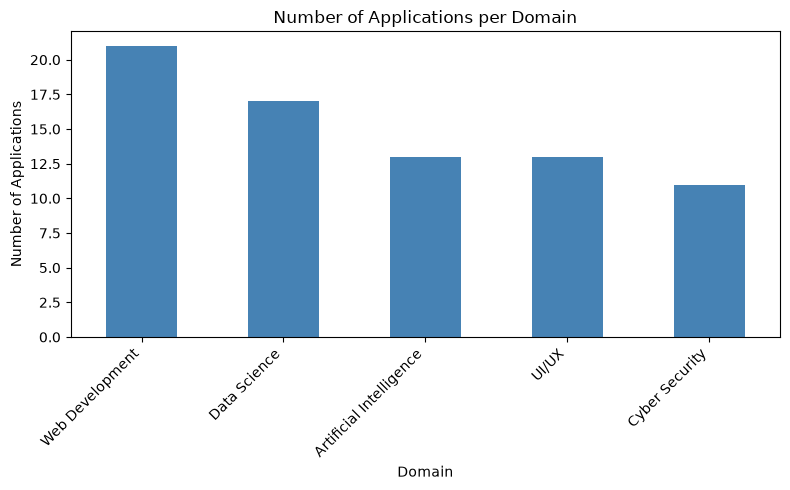

In [9]:
# Count applications for each domain and plot the results
df['Domain Applied'].value_counts().plot.bar(
    figsize=(8, 5),
    color='steelblue'
)

plt.title('Number of Applications per Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
# Takeaway: Web Development received the highest number of applications (21),
# while Cyber Security received the lowest number (11).

## Step 4 — How Did Applications Trend Over Time?

In [10]:
# Extract the month from each application date
df['Application Month'] = df['Application Date'].dt.to_period('M')

# Count applications in each month
monthly_trend = df.groupby('Application Month').size()

# Display the monthly application counts
print(monthly_trend)

Application Month
2025-01    3
2025-02    3
2025-03    4
2025-04    5
2025-05    6
2025-06    4
2025-07    2
2025-08    4
2025-09    4
2025-10    1
2025-11    2
2025-12    1
2026-01    1
2026-02    3
2026-03    6
2026-04    3
2026-05    2
2026-06    2
2026-07    1
2026-08    8
2026-09    4
2026-10    2
2026-11    3
2026-12    1
Freq: M, dtype: int64


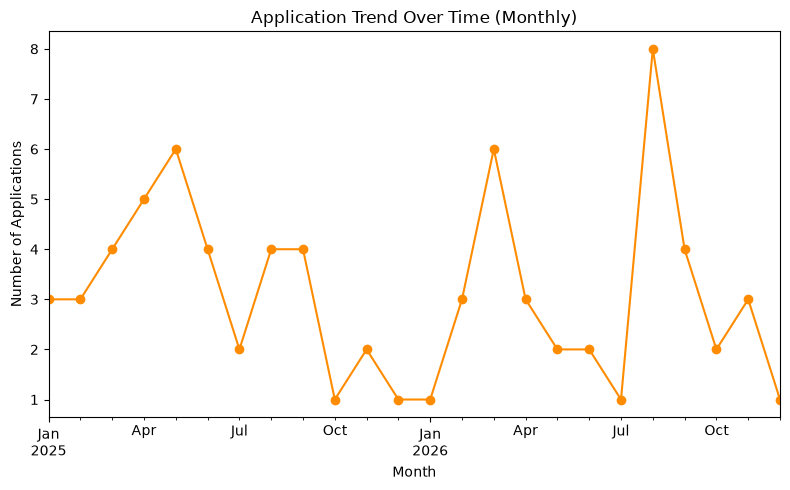

In [11]:
# Plot the monthly application trend
monthly_trend.plot(
    kind='line',
    marker='o',
    color='darkorange',
    figsize=(8, 5)
)

# Add chart title and axis labels
plt.title('Application Trend Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Number of Applications')

plt.tight_layout()
plt.show()

# Takeaway: Applications peaked in August 2026 with 8 applications.

## Step 5 — What's the Acceptance Rate — Overall and Per Domain?

In [12]:
# Count applicants by application status
df['Status'].value_counts()

Status
Under Review    32
Rejected        25
Selected        18
Name: count, dtype: int64

In [13]:
# Count applicants by domain and status
status_by_domain = pd.pivot_table(
    df,
    index='Domain Applied',
    columns='Status',
    values='Applicant Name',
    aggfunc='count',
    fill_value=0
)

# Display the results
print(status_by_domain)

Status                   Rejected  Selected  Under Review
Domain Applied                                           
Artificial Intelligence         4         3             6
Cyber Security                  4         5             2
Data Science                    4         4             9
UI/UX                           6         2             5
Web Development                 7         4            10


In [14]:
# Calculate the percentage of each status within each domain
status_by_domain_pct = (
    status_by_domain.div(status_by_domain.sum(axis=1), axis=0) * 100
)

# Display percentages rounded to one decimal place
print(status_by_domain_pct.round(1))

Status                   Rejected  Selected  Under Review
Domain Applied                                           
Artificial Intelligence      30.8      23.1          46.2
Cyber Security               36.4      45.5          18.2
Data Science                 23.5      23.5          52.9
UI/UX                        46.2      15.4          38.5
Web Development              33.3      19.0          47.6


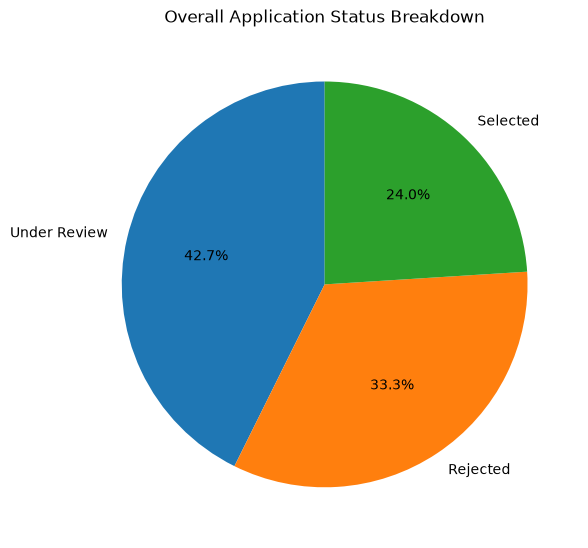

In [15]:
# Plot the overall distribution of application statuses
df['Status'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    figsize=(6, 6)
)

# Add chart title and remove the default y-axis label
plt.title('Overall Application Status Breakdown')
plt.ylabel('')

plt.tight_layout()
plt.show()

# Takeaway: Under Review is the largest status group,
# followed by Rejected and then Selected.

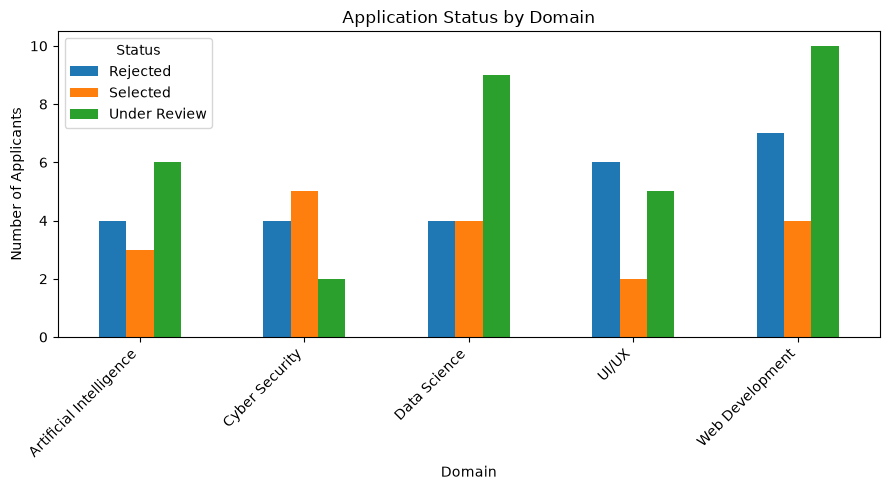

In [16]:
# Plot application status counts for each domain
pd.pivot_table(
    df,
    index='Domain Applied',
    columns='Status',
    values='Applicant Name',
    aggfunc='count',
    fill_value=0
).plot(kind='bar', figsize=(9, 5))

# Add chart title and axis labels
plt.title('Application Status by Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applicants')

# Rotate domain labels and add a legend
plt.xticks(rotation=45, ha='right')
plt.legend(title='Status')

plt.tight_layout()
plt.show()

# Takeaway: Cyber Security has the highest number of selected applicants (5),
# while Web Development has the highest number of applicants under review (10).

## Step 6 — Which Universities Sent the Most Applicants?

In [17]:
# Count applicants from each university and select the top 10
df['University'].value_counts().head(10)

University
Zagazig University       14
BUE                      10
Not Specified            10
AUC                       9
Helwan Univ.              7
Ain Shams University      6
Helwan University         6
Cairo University          5
Alexandria University     5
Mansoura University       3
Name: count, dtype: int64

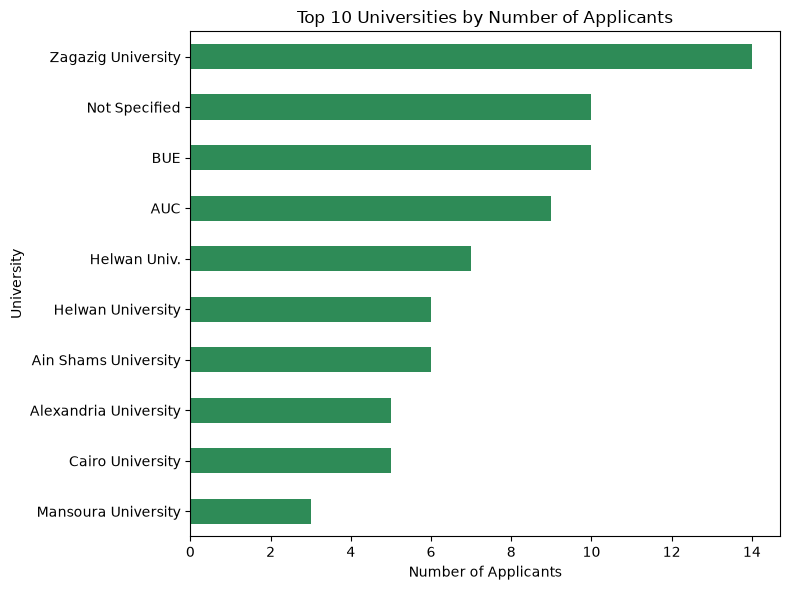

In [18]:
# Count applicants from each university and select the top 10
df['University'].value_counts().head(10).sort_values().plot.barh(
    figsize=(8, 6),
    color='seagreen'
)

# Add chart title and axis labels
plt.title('Top 10 Universities by Number of Applicants')
plt.xlabel('Number of Applicants')
plt.ylabel('University')

plt.tight_layout()
plt.show()

# Takeaway: Zagazig University contributed the highest number of applicants (14).
# Note: "Not Specified" represents applicants whose university was not specified.

## Step 7 — Bonus Chart: Applications by Day of the Week

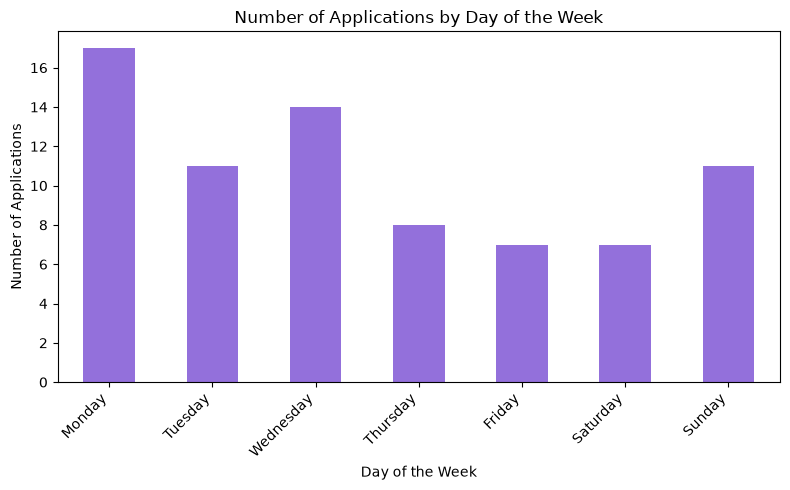

In [20]:
# Count applications by day of the week
df['Application Date'].dt.day_name().value_counts().reindex(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
     'Friday', 'Saturday', 'Sunday'],
    fill_value=0
).plot.bar(figsize=(8, 5), color='mediumpurple')

# Add chart title and axis labels
plt.title('Number of Applications by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Applications')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Reason: This chart helps explore whether application activity
# differs across weekdays and weekends.

## Step 8 — Key Insights

In [21]:
# Key Insights

# 1. Web Development received the highest number of applications (21),
# while Cyber Security received the lowest number (11).

# 2. Applications peaked in August 2026, with 8 applications in that month.

# 3. Cyber Security had the highest selection rate among the five domains,
# at 45.5% (5 out of 11 applicants).

# 4. UI/UX had the highest rejection rate, at 46.2% (6 out of 13 applicants).

# 5. Zagazig University contributed the highest number of applicants (14).